# ERCOT 2025 Electricity Demand Analysis

## Project Overview
As a chemical engineer transitioning into data science, I wanted my first portfolio project to go beyond textbook datasets and explore a real-world engineering problem. Living in Texas, I chose to analyze the Electric Reliability Council of Texas (ERCOT) 2025 Native Load Dataset to better understand electricity demand patterns and build my first end-to-end data analysis workflow. 

Electricity demand is measured in megawatts (MW), representing the rate at which electricity is being consumed at a given time. Electricity consumption is measured in megawatt-hours (MWh), representing the total energy consumed over a period.

For example, a constant demand of 1 MW sustained for one hour corresponds to 1 MWh of energy consumption.

The ERCOT dataset provides hourly electricity-load observations expressed in MW. The Hour Ending column identifies the end of each reporting interval; for example, 18:00 represents the hour ending at 6:00 PM (approximately 5:00–6:00 PM).

**Objective:** Analyzed 2025 hourly ERCOT electricity-load data to identify temporal, seasonal, and regional demand patterns across Texas.  

**Dataset:** 8,760 hourly observations covering ERCOT system load and eight weather zones.  

**Dataset Variable Description:**
- Hour Ending: One hour-ending observation of load for eight weather zones and ERCOT system total  
- COAST: Coast geographical weather zone covering Houston, Galveston, Corpus Christi    
- EAST: East geographical weather zone covering Tyler, Longview, Lufkin, Texarkana  
- FWEST: Far West geographical weather zone covering El Paso, Pecos  
- NORTH: North geographical weather zone covering Wichita Falls, Abilene, Lubbock  
- NCENT: North Central geographical weather zone covering Dallas, Fort Worth, Waco, Arlington  
- SOUTH: Southern geographical weather zone covering Brownsville, McAllen, Laredo  
- SCENT: South Central geographical weather zone covering Austin, San Antonio  
- WEST: West geographical weather zone covering Midland, Odessa, San Angelo  
- ERCOT: Total electricity load/demand per hour ending for the year 2025  

**Tools:** Python, pandas, NumPy, Matplotlib  

_This project is mainly an exploratory/descriptive analysis and does not attempt to determine the causal drivers of demand._

## 1. Data Loading & Inspection

In [1]:
# ERCOT 2025 Electricity Demand Analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.options.display.max_columns = None
pd.set_option('display.expand_frame_repr', False) #prevent pandas from breaking columns onto new lines when displaying df
pd.set_option('display.width', 1000) #set wide width to display all columns in df

filename = '../Data/Native_Load_2025.xlsx'

df = pd.read_excel(filename)
print("Dataset dimensions:", df.shape)
df.head(5)

Dataset dimensions: (8760, 10)


,Hour Ending,COAST,EAST,FWEST,NORTH,NCENT,SOUTH,SCENT,WEST,ERCOT
0,01/01/2025 01:00,10538.553193,1545.465863,7090.619810,1388.565588,11964.866264,3012.769998,6447.297871,1235.721317,43223.859905
1,01/01/2025 02:00,10477.912860,1553.994477,7040.460607,1390.392647,12064.919506,2962.803597,6382.650858,1249.397659,43122.532212
2,01/01/2025 03:00,10363.015361,1534.575620,7028.741719,1390.634577,12040.262276,2981.433181,6320.119991,1259.729121,42918.511847
3,01/01/2025 04:00,10259.984795,1548.084385,6992.734978,1402.423965,12055.424000,2970.761172,6277.132219,1274.238069,42780.783583
4,01/01/2025 05:00,10332.692971,1585.772017,7026.066195,1425.900669,12307.605237,2975.631819,6298.522746,1301.043053,43253.234707


Observation: The data contains 10 columns, with the first column being the timestamp (date & time) and the last column being the total ERCOT demand. Columns 2-9 represent different weather zones within ERCOT. The data has a total of 8760 rows, which corresponds to the number of hours in a non-leap year (365 days * 24 hours).

## 2. Data Wrangling (Quality Checks)

### 2.1 Check for missing values and data types

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Hour Ending  8760 non-null   str    
 1   COAST        8760 non-null   float64
 2   EAST         8760 non-null   float64
 3   FWEST        8760 non-null   float64
 4   NORTH        8760 non-null   float64
 5   NCENT        8760 non-null   float64
 6   SOUTH        8760 non-null   float64
 7   SCENT        8760 non-null   float64
 8   WEST         8760 non-null   float64
 9   ERCOT        8760 non-null   float64
dtypes: float64(9), str(1)
memory usage: 821.4 KB


Observation: The output of df.info() shows that there are no missing values in the dataset. The first column (Hour Ending) is a string and will need to be converted for time-based analysis, while the other columns are float datatype.

### 2.2 Check for duplicate rows

In [3]:
print('Duplicates:', df.duplicated().sum())

Duplicates: 0


Observation: No fully duplicated rows were identified. However, repeated local hour labels can still occur during daylight-saving transitions, which are investigated separately in Section 2.4.

### 2.3 Validate ERCOT total

In [4]:
wrong_row_sum = ~np.isclose(df.iloc[:, 1:9].sum(axis=1), df.iloc[:, 9])
print('Total rows with wrong ERCOT:', int(wrong_row_sum.sum()))

Total rows with wrong ERCOT: 0


Observation: The output shows that there are 0 rows with incorrect ERCOT total, which indicates that the sum of the individual regions matches the total ERCOT demand for all rows. Using the '==' operator to compare the mismatched rows originally showed that 6,364 rows had incorrect ERCOT totals, which was due to floating-point precision issues. Using np.isclose resolved this issue and confirms that the data is accurate.

### 2.4 Validate hourly sequence in data

#### Investigative DST Times

In [5]:
dst_time = df[df.iloc[:,0].str.contains("DST")] #find DST index in Nov
dst_time_fall =df.loc[dst_time.index[0] -3 : dst_time.index[0] +3] #see how time progressed when DST happened

print('Fall DST Time Found:')
print(dst_time_fall)

print("\nSpring DST Time Found:")
dst_time_spring = df[df.iloc[:,0].str.contains("03/09/2025")] #also find missing index in Mar due to DST
print(df.loc[dst_time_spring.index[0] : dst_time_spring.index[0] +8])

Fall DST Time Found:
               Hour Ending         COAST         EAST        FWEST        NORTH         NCENT        SOUTH        SCENT         WEST         ERCOT
7318      11/01/2025 24:00  10951.795177  1360.568488  7245.650343  1158.973008  10589.611351  3745.864963  6785.352580  1170.423139  43008.239050
7319      11/02/2025 01:00  10674.920091  1335.799517  7391.011283  1138.086467  10231.819954  3527.436789  6201.136936  1158.884273  41659.095309
7320      11/02/2025 02:00  10354.600289  1281.896252  7243.931052  1082.375563   9842.264861  3379.591553  5989.608993  1134.937713  40309.206275
7321  11/02/2025 02:00 DST  10157.466148  1257.118263  7314.137127  1065.831053   9595.716227  3287.662656  5869.605272  1122.569795  39670.106541
7322      11/02/2025 03:00  10077.345423  1210.055479  7271.031345  1060.357239   9496.594934  3141.069788  5738.422579  1108.663941  39103.540726
7323      11/02/2025 04:00  10040.251093  1210.144782  7266.623359  1061.935026   9507.228765  30

Observation: The Daylight Saving Time (DST) occurred in November 2, 2025 at 2:00 AM in the fall since there seemed to be duplicate 2:00 AM times, this corresponds to an hour being added for DST. The data also shows a corresponding hour being missed during the DST in spring on March 9, 2025, where there is no 3:00 AM record.

#### Clean-up Hour Ending

In [6]:
hour_ending_copy = df["Hour Ending"].copy() 
contains_24 = hour_ending_copy.str.contains("24:00")

hour_ending_copy = hour_ending_copy.str.replace("24:00", "00:00") #change 24:00 to 00:00
hour_ending_copy = hour_ending_copy.str.replace(" DST", "") #remove DST
hour_ending_copy = pd.to_datetime(hour_ending_copy, format="%m/%d/%Y %H:%M") #convert str to pandas datetime datatype

hour_ending_copy[contains_24] = hour_ending_copy[contains_24] + pd.Timedelta(days=1) #add one day to represent midnight time

print("Original ERCOT Timestamp: ", df.loc[23, "Hour Ending"]) #verify that the cleanup worked
print("Cleaned timestamp: ", hour_ending_copy.loc[23])

timestamp_diff = hour_ending_copy.diff() #check time difference between consecutive observations
timestamp_diff.value_counts() 

# Cleanup is required because ERCOT's Hour Ending from 11:00 PM to 12:00 AM is represented as 24:00 of the same day. This is not a valid 
# timestamp for pandas coding which runs strictly from 00:00 midnight to 23:59. Midnight is represented as 00:00 of the next day.

Original ERCOT Timestamp:  01/01/2025 24:00
Cleaned timestamp:  2025-01-02 00:00:00


Hour Ending
0 days 01:00:00    8757
0 days 02:00:00       1
0 days 00:00:00       1
Name: count, dtype: int64

Observation: After converting the ERCOT timestamps to pandas date-time and correctly handling the 24:00 convention, 8,757 consecutive observations had the expected 1-hour difference. The only exceptions were the 2-hour difference during the March DST transition due to the hour missed and one 0-hour difference during the November DST transition, when the local clock hour was repeated. These are expected DST effects rather than unexplained gaps or duplicate records. Therefore, the hourly sequence appears complete.

### 2.5 Insert Cleaned-up Timestamp column in DF

In [7]:
df.insert(1, "Timestamp", hour_ending_copy) #add cleaned up timestamp to existing dataframe as second column

print(df.head())
print(df.info())

        Hour Ending           Timestamp         COAST         EAST        FWEST        NORTH         NCENT        SOUTH        SCENT         WEST         ERCOT
0  01/01/2025 01:00 2025-01-01 01:00:00  10538.553193  1545.465863  7090.619810  1388.565588  11964.866264  3012.769998  6447.297871  1235.721317  43223.859905
1  01/01/2025 02:00 2025-01-01 02:00:00  10477.912860  1553.994477  7040.460607  1390.392647  12064.919506  2962.803597  6382.650858  1249.397659  43122.532212
2  01/01/2025 03:00 2025-01-01 03:00:00  10363.015361  1534.575620  7028.741719  1390.634577  12040.262276  2981.433181  6320.119991  1259.729121  42918.511847
3  01/01/2025 04:00 2025-01-01 04:00:00  10259.984795  1548.084385  6992.734978  1402.423965  12055.424000  2970.761172  6277.132219  1274.238069  42780.783583
4  01/01/2025 05:00 2025-01-01 05:00:00  10332.692971  1585.772017  7026.066195  1425.900669  12307.605237  2975.631819  6298.522746  1301.043053  43253.234707
<class 'pandas.DataFrame'>
RangeIndex: 8

Observation: The cleaned-up Hour Ending column named 'Timestamp' was added to the dataframe and it correctly has the pandas datetime type.

## 3. EDA & Data Visualization

### Q1: What did overall ERCOT electricity demand look like during 2025?

In [8]:
df["ERCOT"].describe()

count     8760.000000
mean     55734.426774
std      10140.327310
min      38362.786561
25%      48151.649697
50%      53407.199605
75%      61998.615791
max      83679.001697
Name: ERCOT, dtype: float64

Observation: Result show ERCOT's average hourly demand in 2025 was approximately 55,734 MW, with a median of 53,407 MW. The standard deviation of approximately 10,140 infers substantial variability in hourly electricity demand throughout the year. Demand ranged from approximately 38,363 MW to 83,679 MW, suggesting meaningful variation in system load across different time periods.

### Q2. When did ERCOT experience its highest and lowest hourly demand in 2025?

In [9]:
max_index = df["ERCOT"].idxmax() #find highest hourly demand
print("Highest hourly demand:", df.iloc[max_index])

min_index = df["ERCOT"].idxmin() #find lowest hourly demand
print("Lowest hourly demand:", df.iloc[min_index])

Highest hourly demand: Hour Ending       08/18/2025 18:00
Timestamp      2025-08-18 18:00:00
COAST                 22349.497921
EAST                   2888.690723
FWEST                   7046.24676
NORTH                  1942.520791
NCENT                 26581.624761
SOUTH                  6508.846311
SCENT                  14519.96276
WEST                   1841.611669
ERCOT                 83679.001697
Name: 5512, dtype: object
Lowest hourly demand: Hour Ending       05/04/2025 05:00
Timestamp      2025-05-04 05:00:00
COAST                 10447.536663
EAST                   1081.497975
FWEST                  6887.145416
NORTH                    1148.0546
NCENT                  9108.733157
SOUTH                  3233.379026
SCENT                  5454.431866
WEST                   1002.007857
ERCOT                 38362.786561
Name: 2955, dtype: object


Observation: The highest hourly demand occurred at the timestamp corresponding to the maximum value, which was August 18, 2025 at 6pm, while the lowest hourly demand occurred at the timestamp corresponding to the minimum value, which was May 4, 2025 at 5am.

### Q3. How did average ERCOT demand vary by hour of day?

Highest average hour and demand: 18 , 63394.140381331505
Lowest average hour and demand: 4 , 47356.170511358905
Percentage change between highest and lowest average hour: 33.87%


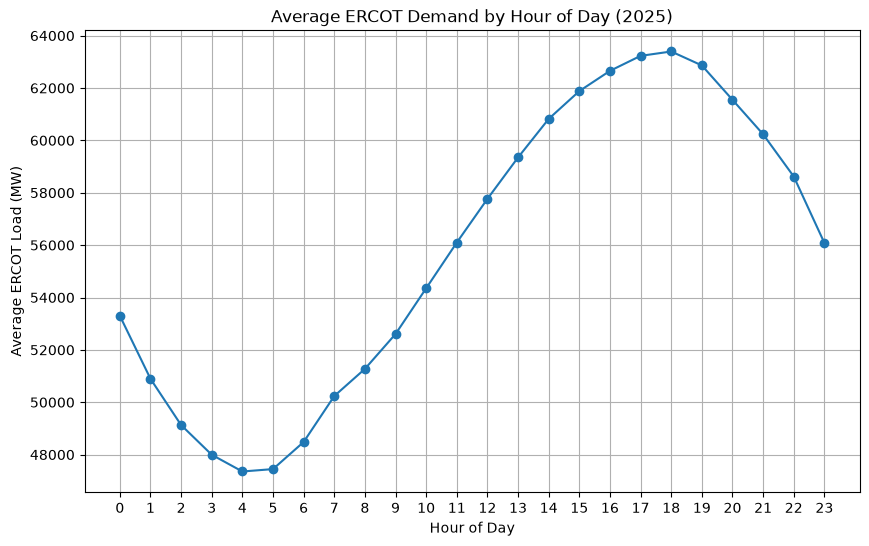

In [10]:
df["Hour"] = df["Timestamp"].dt.hour #create an hour column
hourly_avg = df.groupby("Hour")["ERCOT"].mean() #group observations according to hour of day, and avg ERCOT load within each group
#print(hourly_avg)

print("Highest average hour and demand:", hourly_avg.idxmax(), ',', hourly_avg.max()) 
print("Lowest average hour and demand:", hourly_avg.idxmin(), ',', hourly_avg.min())

percent_change = (hourly_avg.max() - hourly_avg.min()) / hourly_avg.min() * 100
print(f"Percentage change between highest and lowest average hour: {percent_change:.2f}%")

plt.figure(figsize=(10,6))
plt.plot(hourly_avg.index, hourly_avg.values, marker='o')
plt.title("Average ERCOT Demand by Hour of Day (2025)")
plt.xlabel("Hour of Day")
plt.ylabel("Average ERCOT Load (MW)")
plt.grid(True)
plt.xticks(range(0, 24))
plt.show()

Observation: In 2025, ERCOT's average hourly demand was lowest around 4:00 AM at approximately 47,356 MW and highest around 6:00 PM, at approximately 63,394 MW. Average demand typically declined overnight until reaching its lowest point around 4:00 AM, and then started to increase again through the day towards the evening peak around 6:00 PM. It was also observed that the average demand at 6:00 PM was about 33.9% higher than the average demand at 4:00 AM.

### Q4. How did average electricity demand vary across ERCOT's eight weather zones?

Highest average zone and demand: NCENT , 15306.61779808653
Lowest average zone and demand: WEST , 1384.5953985998858
How much of the total ERCOT demand each zone accounts for:
NCENT: 27.46%
COAST: 26.46%
SCENT: 15.93%
FWEST: 13.42%
SOUTH: 7.96%
EAST: 3.26%
NORTH: 3.03%
WEST: 2.48%


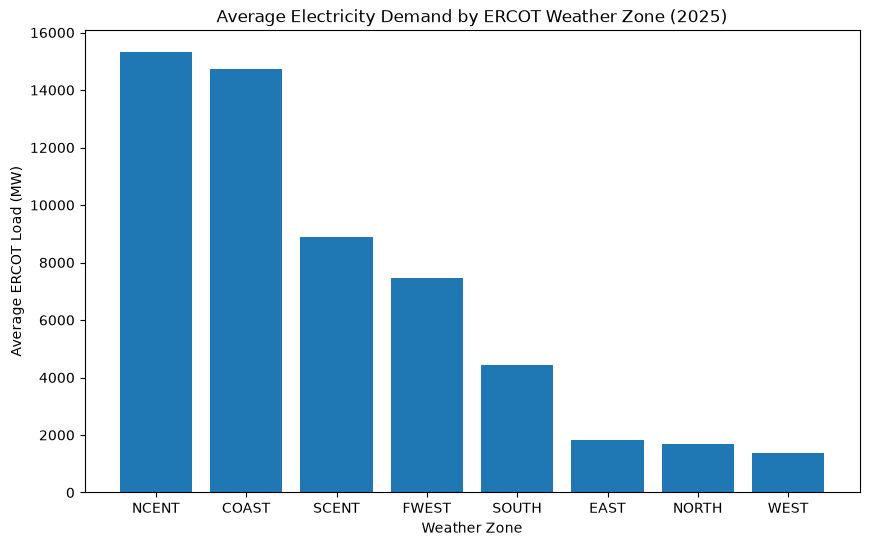

In [11]:
weather_zones = ["COAST", "EAST", "FWEST", "NORTH", "NCENT", "SOUTH", "SCENT", "WEST"]
#print(weather_zones.head())

zone_avg = df[weather_zones].mean() #calculate average hourly load for each weather zone
zone_avg = zone_avg.sort_values(ascending=False)

print("Highest average zone and demand:", zone_avg.idxmax(), ',', zone_avg.max()) 
print("Lowest average zone and demand:", zone_avg.idxmin(), ',', zone_avg.min())

print("How much of the total ERCOT demand each zone accounts for:")
zone_share = zone_avg / zone_avg.sum() * 100
for zone, share in zone_share.items():
    print(f"{zone}: {share:.2f}%")

plt.figure(figsize=(10,6))
plt.bar(zone_avg.index, zone_avg.values)
plt.title("Average Electricity Demand by ERCOT Weather Zone (2025)")
plt.xlabel("Weather Zone")
plt.ylabel("Average ERCOT Load (MW)")
plt.grid(False)
plt.show()

Observation: NCENT had the highest average hourly load at approximately 15,307 MW, followed closely by COAST. Together, NCENT and COAST accounted for approximately 53.9% of average ERCOT system load in 2025. SCENT and FWEST contributed another 15.9% and 13.4%, respectively, while EAST, NORTH, and WEST collectively represented only about 8.8%. This indicates that electricity demand was distributed unevenly across ERCOT's eight weather zones.

### Q5a. How did average electricity demand vary by day of the week?

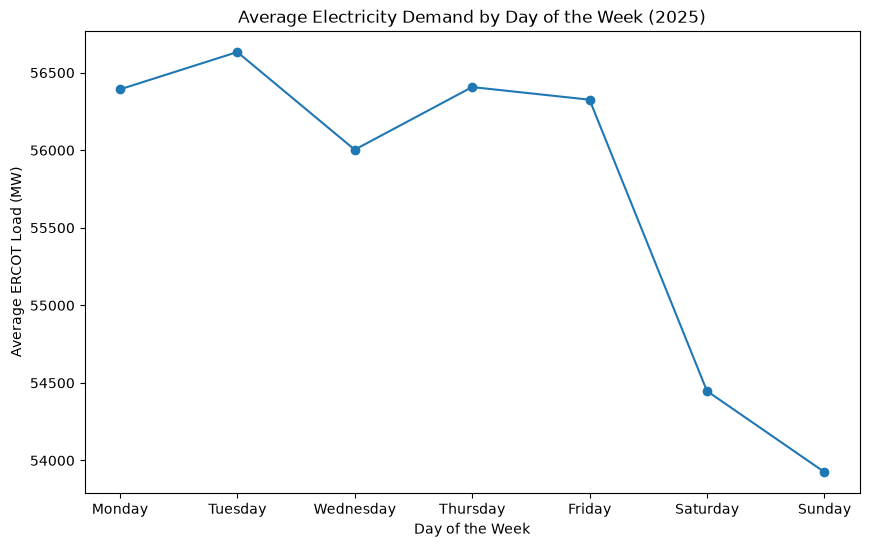

In [12]:
df["DayOfWeek"] = df["Timestamp"].dt.day_name() #extract day of the week from the timestamp
day_avg = df.groupby("DayOfWeek")["ERCOT"].mean() #calculate average electricity demand for each day of the week

day_avg = day_avg.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])

plt.figure(figsize=(10,6))
plt.plot(day_avg.index, day_avg.values, marker='o')
plt.title("Average Electricity Demand by Day of the Week (2025)")
plt.xlabel("Day of the Week")
plt.ylabel("Average ERCOT Load (MW)")
plt.grid(False)
plt.show()

Observation: Tuesday had the highest average load, while Sunday had the lowest. The decline from Friday to Saturday and further decline on Sunday suggests a distinct weekday–weekend demand pattern.

### Q5b. How much higher was average weekday demand than average weekend demand?

In [13]:
df["IsWeekend"] = df["DayOfWeek"].isin(["Saturday", "Sunday"]) #check if the day is a weekend
df["DayType"] = np.where(df["IsWeekend"], "Weekend", "Weekday") #categorize the day as either weekday or weekend

day_type_avg = df.groupby("DayType")["ERCOT"].mean() #calculate average electricity demand for weekdays and weekends

dayType_percent = (day_type_avg["Weekday"] - day_type_avg["Weekend"]) / day_type_avg["Weekend"] * 100
print(f"Weekday vs Weekend Demand Increase: {dayType_percent:.2f}%")

Weekday vs Weekend Demand Increase: 3.99%


Observation: Average ERCOT load was higher on weekdays than on weekends in 2025, with weekday demand averaging approximately 3.99% higher than weekend demand.

### Q6a. How did electricity demand vary by month throughout 2025?

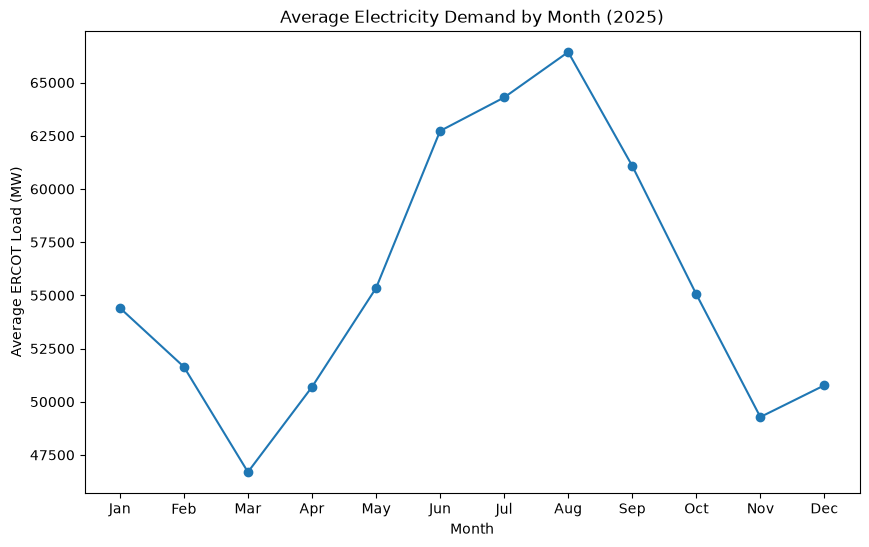

In [14]:
df["Month"] = df["Timestamp"].dt.strftime("%b") #extract month from the timestamp
month_avg = df.groupby("Month")["ERCOT"].mean() #calculate average electricity demand for each month

month_avg = month_avg.reindex(
    ["Jan", "Feb", "Mar", "Apr", "May", 
    "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.figure(figsize=(10,6))
plt.plot(month_avg.index, month_avg.values, marker='o')
plt.title("Average Electricity Demand by Month (2025)")
plt.xlabel("Month")
plt.ylabel("Average ERCOT Load (MW)")
plt.grid(False)
plt.show()

### Q6b. How did electricity demand vary by season throughout 2025?

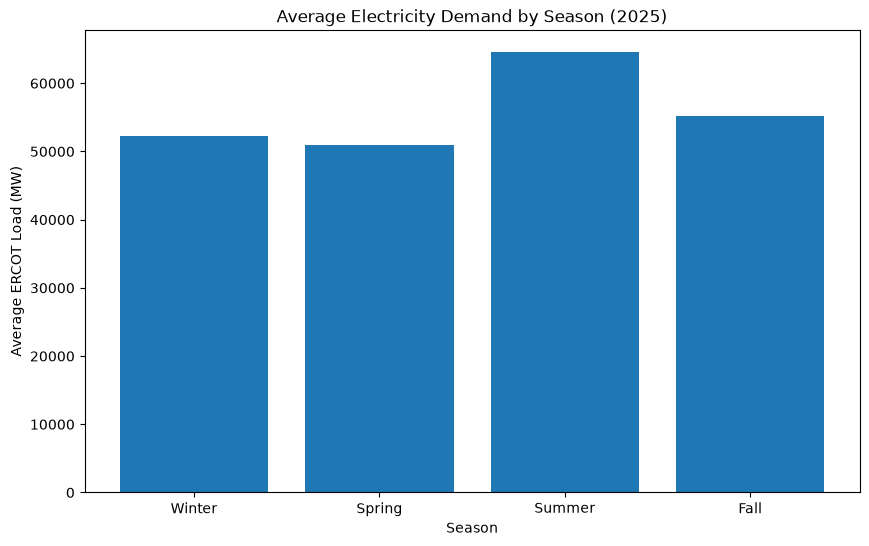

In [15]:
df["Seasons"] = df["Month"].map({
    "Dec": "Winter", "Jan": "Winter", "Feb": "Winter",
    "Mar": "Spring", "Apr": "Spring", "May": "Spring",
    "Jun": "Summer", "Jul": "Summer", "Aug": "Summer",
    "Sep": "Fall", "Oct": "Fall", "Nov": "Fall"
})
season_avg = df.groupby("Seasons")["ERCOT"].mean().reindex(["Winter", "Spring", "Summer", "Fall"])

plt.figure(figsize=(10,6))
plt.bar(season_avg.index, season_avg.values)
plt.title("Average Electricity Demand by Season (2025)")
plt.xlabel("Season")
plt.ylabel("Average ERCOT Load (MW)")
plt.grid(False)
plt.show()

Observation: Average ERCOT load showed a pronounced seasonal pattern in 2025. Monthly average demand was lowest in March, increased substantially from spring into summer, and peaked in August before declining through the fall. At the seasonal level, summer had the highest average load while spring had the lowest. These results demonstrate substantial seasonal variation in ERCOT electricity demand, although this analysis alone does not identify the factors driving that variation.

### Q7. How did hourly electricity demand pattern change across seasons in 2025?

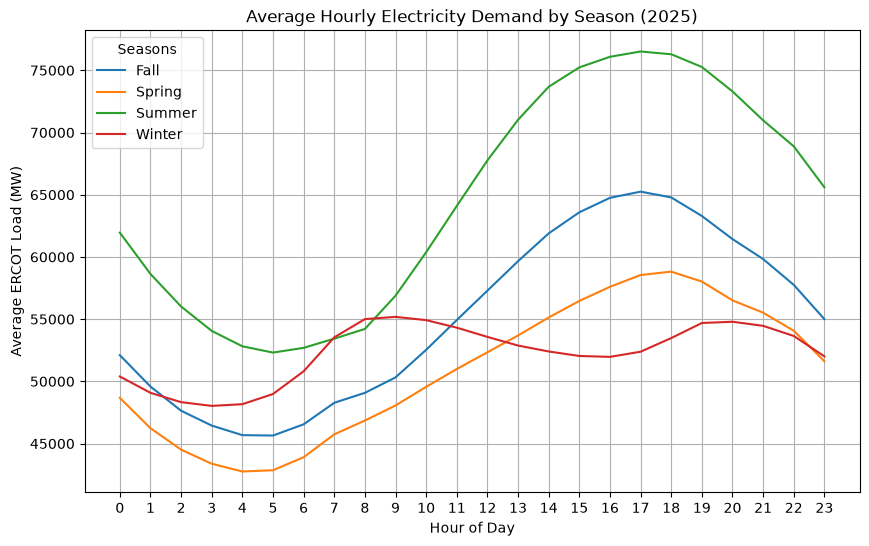

Peak hourly electricity demand by season (2025): Seasons
Fall      17
Spring    18
Summer    17
Winter     9
dtype: int32
Average load at peak hour by season: Seasons
Fall      65249.347731
Spring    58819.268307
Summer    76513.009324
Winter    55185.195579
dtype: float64


In [16]:
season_hour_avg = df.groupby(["Seasons", "Hour"])["ERCOT"].mean().unstack(level=0) 
#season_hour_avg.head()

season_hour_avg.plot(figsize=(10,6))
plt.title("Average Hourly Electricity Demand by Season (2025)")
plt.xlabel("Hour of Day")
plt.ylabel("Average ERCOT Load (MW)")
plt.legend(title="Seasons")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

print("Peak hourly electricity demand by season (2025):", season_hour_avg.idxmax())
print("Average load at peak hour by season:", season_hour_avg.max())

Observation: Hourly electricity-demand patterns varied by season in 2025. Summer had the highest peak average load at approximately 76,513 MW around 5 PM, while fall also peaked around 5 PM and spring around 6 PM. Winter showed a different hourly pattern, reaching its highest average load around 9 AM and showing a smaller secondary increase in the evening. This demonstrates that the annual 6 PM peak calculated earlier does not fully represent demand behavior across all seasons.

### Q8: What patterns characterize ERCOT's highest-demand hours in 2025?

In [17]:
top_10 = df.sort_values(by=["ERCOT"], ascending=False).head(10)[["Timestamp", "Hour", "DayOfWeek", "Month", "ERCOT"]]
top_10

,Timestamp,Hour,DayOfWeek,Month,ERCOT
5512,2025-08-18 18:00:00,18,Monday,Aug,83679.001697
5511,2025-08-18 17:00:00,17,Monday,Aug,83673.625458
5510,2025-08-18 16:00:00,16,Monday,Aug,83098.220898
5751,2025-08-28 17:00:00,17,Thursday,Aug,82907.273669
5750,2025-08-28 16:00:00,16,Thursday,Aug,82858.985674
5513,2025-08-18 19:00:00,19,Monday,Aug,82858.329189
5509,2025-08-18 15:00:00,15,Monday,Aug,82791.521045
5415,2025-08-14 17:00:00,17,Thursday,Aug,82757.910024
5416,2025-08-14 18:00:00,18,Thursday,Aug,82703.220532
5414,2025-08-14 16:00:00,16,Thursday,Aug,82663.421435


Observation: ERCOT's 10 highest-demand hours in 2025 were all concentrated in August and occurred between 3 PM and 7 PM. Five of the top 10 observations occurred consecutively on August 18 from 3 PM through 7 PM, including the annual maximum of approximately 83,679 MW at 6 PM. All top-10 observations occurred on weekdays (Monday or Thursday). These results reinforce the broader patterns identified in the analysis: the highest system loads were concentrated during summer afternoon and evening periods.

## Conclusion

I analyzed ERCOT's 2025 hourly electricity-load data to understand how electricity demand varies across time and Texas weather zones.

I started by validating 8,760 hourly observations, including checking missing values, duplicates, regional totals, and timestamp consistency. One interesting challenge was handling ERCOT's 24:00 timestamp convention and daylight-saving-time transitions.

My analysis showed that North Central and Coast together represented approximately 54% of average ERCOT system load. I also found that demand patterns differed by season. While the annual average peaked around 6 PM, winter's daily average peaked around 9 AM, compared with late-afternoon peaks in other seasons.

One limitation is that I only analyzed 2025 load data, without incorporating weather or other external variables. Moving forward, I have developed and evaluated time-series forecasting models, starting with historical load and calendar features, then investigated whether weather and other grid-related variables improved predictions.

This exploratory analysis provides the foundation for the accompanying forecasting notebook, where I develop historical-load features, compare regression models against persistence baselines, and evaluate day-ahead forecasts on a chronological test period.